# ITI replication: what our data supports

Bogousslavsky, Fos and Muravyev (2024), *Informed Trading Intensity*, JF 79(2).

**Sample:** 2005–7/2019 (the paper uses 1993–7/2019). ITI values are the authors'
posted file (original vintage); we have not trained our own model. Every number
below is read from files built by:

| Step | Command | Output |
|---|---|---|
| 13D trade-day labels | `doit 13d_validation` | `_data/derived/13d/`, `_output/13d_label_validation.md` |
| Stock panels | `doit panel` | `_data/derived/panel/{daily,weekly}.parquet` |
| Exhibits | `doit replication` | `_output/replication/` |

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

import paper_values as pv
from validate_13d_labels import PAPER, label_stats

ROOT = Path("..")
REP = ROOT / "_output" / "replication"
D13 = ROOT / "_data" / "derived" / "13d"
pd.set_option("display.float_format", "{:,.4f}".format)

## 1. Schedule 13D labels (rebuilt from SEC filing text)

The authors' label file is not public, so we rebuild it from 27,622 original SC 13D
filings. Screens follow paper footnote 5; the funnel shows the first failed screen.

In [2]:
events = pd.read_parquet(D13 / "events.parquet")
labels = pd.read_parquet(D13 / "labels_daily.parquet")
funnel = events.exclusion_reason.fillna("included").value_counts().rename("filings").to_frame()
funnel

,filings
exclusion_reason,
linked,11188
common_stock,4160
price,3911
has_trades,3386
included,2193
original,1395
mcap,1272
duplicate_event,59
no_derivatives,58


In [3]:
paper_period = labels[labels.in_paper_period]
ours = label_stats(paper_period)
authors = label_stats(paper_period[paper_period.in_authors_sample.fillna(False)])
compare_13d = pd.DataFrame({
    "ours (2005-2018)": ours,
    "ours, authors' events": authors,
    "paper": {k: v[0] for k, v in PAPER.items()},
    "source": {k: v[1] for k, v in PAPER.items()},
}).drop(index=["filer_shares_gt_crsp_vol"])
compare_13d

,ours (2005-2018),"ours, authors' events",paper,source
events,"2,102.0000",916.0000,NaN,NaN
rows_per_event,40.9933,42.2172,36.5330,"Table 1: 58,197 rows / 1,593 filings"
itrade,0.3630,0.3826,0.3603,Table 1
itrade_patient,0.3214,0.3274,0.3000,Sec. 4.1: 30% of days in first 40
itrade_impatient,0.4404,0.4878,0.4900,Sec. 4.1: 49% of days in last 20
vol_share,0.1424,0.1401,0.2800,Sec. 3.1: 28% of daily volume when trading
vol_share_patient,0.1247,0.1250,0.2000,Sec. 4.1
vol_share_impatient,0.1665,0.1594,0.3700,Sec. 4.1
turn13d_mean_x100,0.2937,0.2419,0.2755,"Table IA.5, trade days"
turn13d_median_x100,0.0780,0.0827,0.1055,"Table IA.5, trade days"


Trade-day frequency matches the paper (0.36). The filer's share of daily volume is
about half the paper's, and sales are a larger share of trade days; both are open
items. Abnormal return around the filing (paper Figure IA.1):

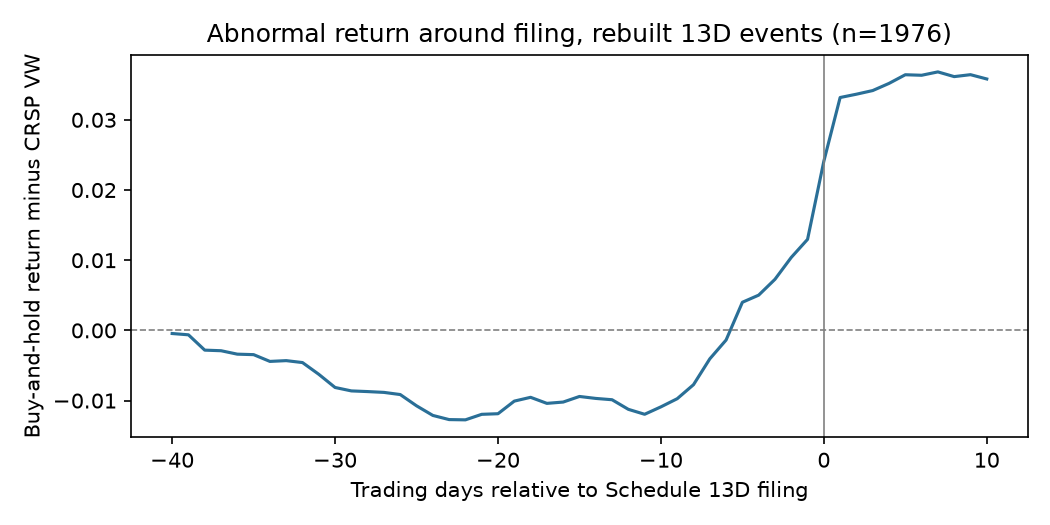

In [4]:
Image(ROOT / "_output" / "13d_filing_car.png", width=650)

## 2. Table 10: weekly ITI predicts next-month returns

Stock-week panel; return over the next 21 trading days after skipping one day,
delisting-adjusted (Shumway). Week fixed effects, errors clustered by stock and week.
Price > \$5 and market cap > \$100M at the previous month end. Column 5 controls:
log size, CAPM beta, last-month and 2–6 month returns, FF4 idiosyncratic volatility,
Amihud illiquidity, effective spread (**Kyle's lambda omitted**: not computed).

In [5]:
def side_by_side(ours_long, paper, nobs_paper):
    rows = []
    for col, spec in paper.items():
        o = ours_long[ours_long.column.astype(str) == str(col)].set_index("variable")
        for var, (pc, pt) in spec.items():
            rows.append({"column": col, "variable": var, "paper coef": pc, "paper t": pt,
                         "ours coef": o.loc[var, "coef"], "ours t": o.loc[var, "t"]})
        rows.append({"column": col, "variable": "Obs.", "paper coef": nobs_paper,
                     "ours coef": o.loc["Obs.", "coef"]})
    return pd.DataFrame(rows).set_index(["column", "variable"])


t10 = pd.read_csv(REP / "table10.csv")
side_by_side(t10, pv.TABLE10, pv.TABLE10_NOBS)

paper coef  paper t      ours coef  ours t
column variable                                                     
1      ITI(13D)               0.0126   6.8200         0.0048  2.8771
       Obs.           3,484,923.0000      NaN 1,913,001.0000     NaN
2      ITI(13D)               0.0117   4.6700         0.0050  2.6673
       ITI(insider)           0.0119   4.8200         0.0011  0.5722
       ITI(short)            -0.0084  -1.2900        -0.0018 -0.3230
       Obs.           3,484,923.0000      NaN 1,913,001.0000     NaN
3      ITI(patient)           0.0006   0.2800        -0.0014 -0.6539
       ITI(impatient)         0.0158   6.5100         0.0078  3.2034
       Obs.           3,484,923.0000      NaN 1,913,001.0000     NaN
4      ITI(13D)               0.0053   2.2200         0.0025  1.1353
       ITI(insider)           0.0107   4.4200         0.0006  0.2902
       ITI(short)            -0.0201  -2.7900        -0.0087 -1.4212
       ITI(patient)          -0.0030  -1.4300        -0.0027 -1.2553
       ITI(impatient)         0.0163   5.8300         0.0090  2.9850
       Obs.           3,484,923.0000      NaN 1,913,001.0000     NaN
5      ITI(13D)               0.0061   3.2300         0.0038  1.7871
       ITI(insider)           0.0094   5.6900         0.0034  1.9899
       ITI(short)            -0.0065  -1.2600        -0.0153 -2.7737
       ITI(patient)          -0.0038  -1.8500        -0.0002 -0.1074
       ITI(impatient)         0.0164   5.2500         0.0063  2.2229
       Obs.           3,484,923.0000      NaN 1,913,001.0000     NaN

In [6]:
t10[(t10.column == 5) & ~t10.variable.str.startswith("ITI")].set_index("variable")[["coef", "t"]]

,coef,t
variable,,
size,0.0001,0.2661
beta,0.0025,2.1329
r_1m,-0.0032,-0.6401
r_2_6m,0.0013,0.7074
ivol,-0.1481,-4.0452
illiq,0.0007,2.0632
es_m,-0.1896,-2.2871
Obs.,"1,913,001.0000",NaN
R2 (within),0.0005,NaN


Signs match for ITI(13D), ITI(impatient) and ITI(short); ITI(impatient) beats
ITI(patient) as in the paper. Coefficients are roughly 40% of the paper's and
t-statistics about half, consistent with weaker return predictability after 2005.
ITI(insider) is weak here.

## 3. Table 11: decile portfolios on prior-week ITI

Equal-weighted, next-month return (same window as Table 10); weekly overlapping
observations, Newey-West with 8 lags. Alphas from FF4 factors compounded over the
same window.

In [7]:
t11 = pd.read_csv(REP / "table11.csv")
order = ["Low", "2", "3", "4", "5", "6", "7", "8", "9", "High", "H-L"]
alpha = t11.pivot(index="measure", columns="portfolio", values="alpha")[order]
paper_alpha = pd.DataFrame(pv.TABLE11_ALPHA, index=order).T
hl = t11[t11.portfolio == "H-L"].set_index("measure")[["raw", "raw_t", "alpha", "alpha_t"]]
hl["paper raw"] = pd.Series({k: v[-1] for k, v in pv.TABLE11_RAW.items()})
hl["paper raw t"] = pd.Series(pv.TABLE11_RAW_HL_T)
hl["paper alpha"] = pd.Series({k: v[-1] for k, v in pv.TABLE11_ALPHA.items()})
hl["paper alpha t"] = pd.Series(pv.TABLE11_ALPHA_HL_T)
hl

,raw,raw_t,alpha,alpha_t,paper raw,paper raw t,paper alpha,paper alpha t
measure,,,,,,,,
ITI(13D),0.0015,1.7558,0.0017,2.0803,0.0044,4.9000,0.0052,6.2000
ITI(insider),0.0003,0.3793,-0.0001,-0.1198,0.0037,3.3000,0.0022,2.9000
ITI(short),0.0012,1.0413,-0.0002,-0.1532,0.0014,1.0000,0.0005,0.5000
ITI(patient),0.0009,1.1531,0.0010,1.3151,0.0030,3.9000,0.0034,4.2000
ITI(impatient),0.0024,2.5525,0.0020,2.2262,0.0051,5.1000,0.0054,5.7000


In [8]:
display(Markdown("**FF4 alphas by decile, ours**"))
display(alpha)
display(Markdown("**FF4 alphas by decile, paper**"))
paper_alpha

**FF4 alphas by decile, ours**

portfolio,Low,2,3,4,5,6,7,8,9,High,H-L
measure,,,,,,,,,,,
ITI(13D),-0.0006,-0.0009,-0.0005,-0.0004,-0.0005,0.0001,0.0002,0.0006,0.0009,0.0011,0.0017
ITI(impatient),-0.0009,-0.0006,-0.0007,-0.0002,0.0001,0.0004,0.0004,0.0003,0.0001,0.0011,0.0020
ITI(insider),-0.0002,-0.0000,-0.0002,0.0001,0.0005,0.0006,0.0002,0.0004,0.0003,-0.0003,-0.0001
ITI(patient),-0.0000,-0.0007,-0.0002,-0.0005,-0.0002,-0.0002,0.0004,0.0003,0.0000,0.0010,0.0010
ITI(short),0.0001,0.0004,0.0006,-0.0002,0.0005,0.0002,-0.0003,-0.0000,-0.0000,-0.0001,-0.0002


**FF4 alphas by decile, paper**

,Low,2,3,4,5,6,7,8,9,High,H-L
ITI(13D),-0.0003,0.0005,0.0007,0.0014,0.0017,0.0013,0.0027,0.0027,0.0035,0.0049,0.0052
ITI(insider),0.0003,0.0010,0.0016,0.0020,0.0018,0.0024,0.0021,0.0028,0.0025,0.0026,0.0022
ITI(short),0.0017,0.0016,0.0015,0.0017,0.0020,0.0014,0.0021,0.0024,0.0025,0.0022,0.0005
ITI(patient),0.0008,0.0007,0.0011,0.0014,0.0016,0.0018,0.0024,0.0023,0.0027,0.0041,0.0034
ITI(impatient),-0.0006,0.0004,0.0006,0.0015,0.0018,0.0021,0.0025,0.0030,0.0032,0.0048,0.0054


High-minus-low FF4 alphas are positive and significant for ITI(13D) and
ITI(impatient), insignificant for ITI(short), as in the paper, but about a third
of the paper's size. ITI(insider) and ITI(patient) are not significant here.

## 4. Table 5: return reversal is weaker on high-ITI days

Daily ret(t+1) on ret(t), ITI(13D) and their interaction, date fixed effects,
errors clustered by stock and date. Column 3 controls come from WRDS Intraday
Indicators (effective spread, price impact, depth, intraday volatility, order
imbalance) and CRSP turnover; **lambda omitted**. "2 (col 3 sample)" re-runs
column 2 on the rows with all controls.

In [9]:
t5 = pd.read_csv(REP / "table5.csv")
side_by_side(t5, pv.TABLE5, pv.TABLE5_NOBS)

paper coef  paper t      ours coef  ours t
column variable                                                    
1      ret                  -0.0040  -1.7740        -0.0124 -4.3518
       Obs.         16,814,168.0000      NaN 9,567,779.0000     NaN
2      ret                  -0.0140  -4.4770        -0.0305 -7.0526
       ITI(13D)              0.0020  23.5530         0.0013 13.3259
       ret*ITI(13D)          0.0310   6.4450         0.0463  7.3602
       Obs.         16,814,168.0000      NaN 9,567,779.0000     NaN
3      ret                  -0.0060  -1.9770        -0.0131 -3.2865
       ITI(13D)              0.0020  20.0010         0.0013 12.5776
       ret*ITI(13D)          0.0340   5.8300         0.0273  4.5022
       ret*turn              0.0080   0.5410         0.0546  2.0067
       ret*rvol             -0.0290  -1.6520       -79.4347 -2.0409
       ret*ES%              -0.7560  -4.9360        -2.5363 -6.1690
       Obs.         16,814,168.0000      NaN 9,318,834.0000     NaN

The key result replicates: ret×ITI(13D) is positive and significant (t ≈ 7 without
controls, 4.5 with). Units of our spread and volatility controls differ from the
paper's, so their interaction coefficients are not comparable in size.

## 5. Figure 4(a)–(b): ITI(13D) around earnings announcements

Compustat `rdq` linked through CCM; day 0 is the higher-volume of the reported day
and the next trading day. Stock fixed effects; errors clustered by stock and date;
bars are 95% intervals. Panel (b) puts top, middle and bottom quartiles of
|day-0 return| in one regression. Dashed lines are read off the paper's plots.

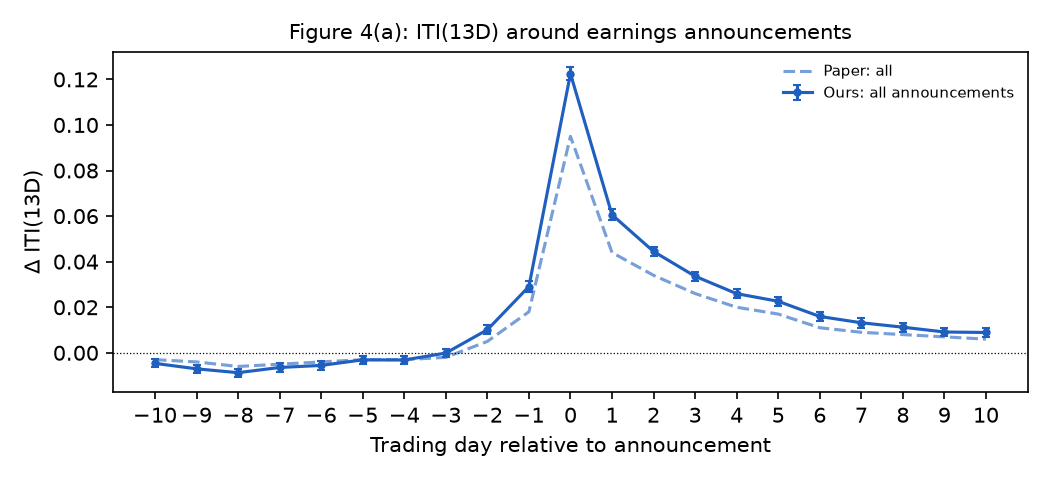

In [10]:
Image(REP / "figure4a.png", width=700)

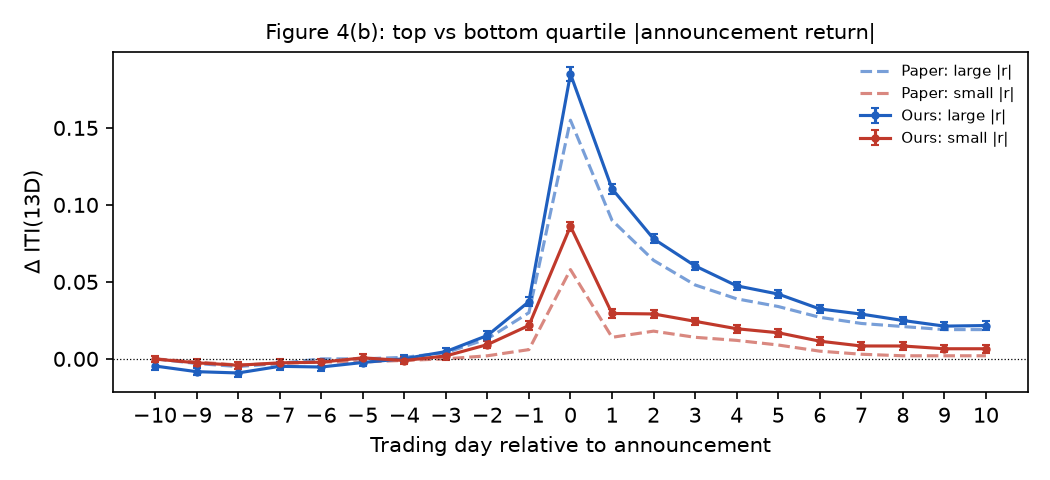

In [11]:
Image(REP / "figure4b.png", width=700)

Same shape as the paper: ITI rises from day −2, spikes on day 0, decays over ten
days, and the spike is larger for large-|r| announcements.

## 6. Figure IA.5: ITI(13D) around M&A announcements

SDC completed acquisitions of US public targets (merger, acquisition, majority or
remaining interest), linked by 6-digit CUSIP.

Events: 2,857 (paper: 1,577, 1996–2010)

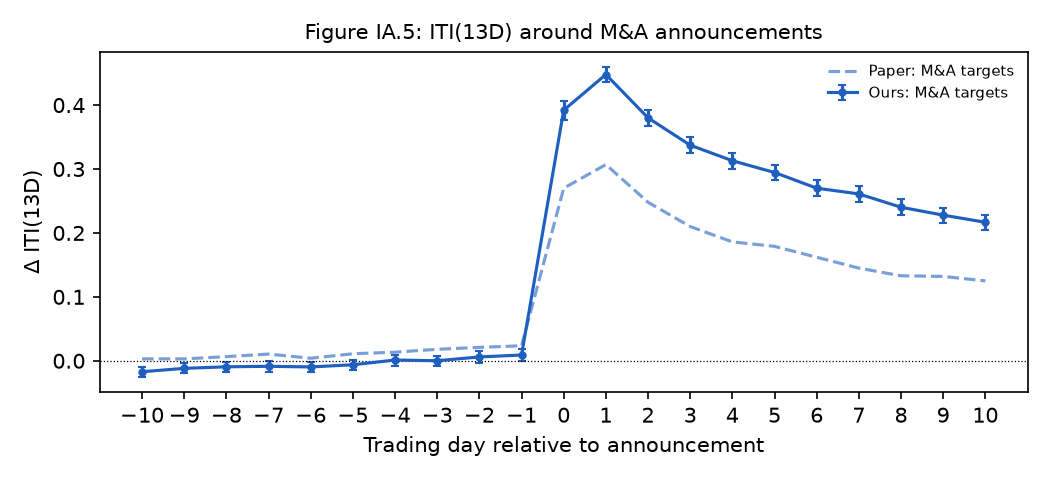

In [12]:
fia5 = pd.read_csv(REP / "figureIA5.csv")
display(Markdown(f"Events: {fia5.n_events.iloc[0]:,} (paper: {pv.FIGIA5_EVENTS:,}, 1996–2010)"))
Image(REP / "figureIA5.png", width=700)

The post-announcement jump replicates and is larger than the paper's; the paper's
small pre-announcement run-up (days −5 to −1) does not appear in our sample.

## 7. Not replicated, and what is needed

| Exhibit | Missing input |
|---|---|
| Our own ITI model; Tables 2–4, 7, 8; rest of Table 6 | TAQ-built daily features and controls (compute on WRDS, ~2–4 GB) |
| Table 10 col 6 | Brown–Hillegeist annual PIN (authors' replication ZIP) |
| Table 10 Panel B | ITI(insider buy/sell): not posted; needs our own model |
| Lambda in Tables 5, 10 controls | Kyle's lambda from TAQ trades |
| Figure 4(c), Table 6 cols 5–6 | BFKR news file (public; on teammate's `bfkr-news` branch, not merged) |
| Table 6 col 7 | Ahern (2020) illegal insider trades |
| Table 9 | BCL measure |
| Insider-trained ITI from scratch | Insider trades before 2004 (routine vs opportunistic) |
| Exact 13D sample | Authors' `sc13_1994_2018.dta` (not public) |
| Full 1993–2019 period | All inputs for 1993–2004 (~30–40 GB) |